Importing libraries.

In [1]:
#import libraries.
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import v2
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import f1_score, classification_report, confusion_matrix, precision_score, recall_score, accuracy_score
from torchinfo import summary
import torchvision.models as models
import pandas as pd

data augmentation and data loader

In [2]:

# transform hyper parameters.
img_size = 224

# transform for training data.
# for more information about data augmentation, please refere to this following article.
# Goceri E. Medical image data augmentation: techniques, comparisons and interpretations. Artif Intell Rev. 2023 Mar 20:1-45. doi: 10.1007/s10462-023-10453-z. Epub ahead of print. PMID: 37362888; PMCID: PMC10027281.
train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((img_size, img_size)),
    v2.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(10),
    v2.RandomAffine(degrees=0, translate=(0.05, 0.05)),
])

#transform for test/valid data.
valid_test_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((img_size, img_size)),
    v2.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5))

])

transform_no_augment = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((img_size, img_size)),
    v2.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5)),

])

#base directory of the dataset.
base_data_path = Path("/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data")

_batch_size = 32

# train dataset.
train_data_path = base_data_path / "train"
train_dataset = datasets.ImageFolder(root=train_data_path, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=_batch_size, shuffle=True)

# valid dataset.
valid_data_path = base_data_path / "valid"
valid_dataset = datasets.ImageFolder(root=valid_data_path, transform=valid_test_transform)
valid_loader = DataLoader(valid_dataset, batch_size=_batch_size, shuffle=False)

# test dataset.
test_data_path = base_data_path / "test"
test_dataset = datasets.ImageFolder(root=test_data_path, transform=valid_test_transform)
test_loader = DataLoader(test_dataset, batch_size=_batch_size, shuffle=False)


class labels, and visualization

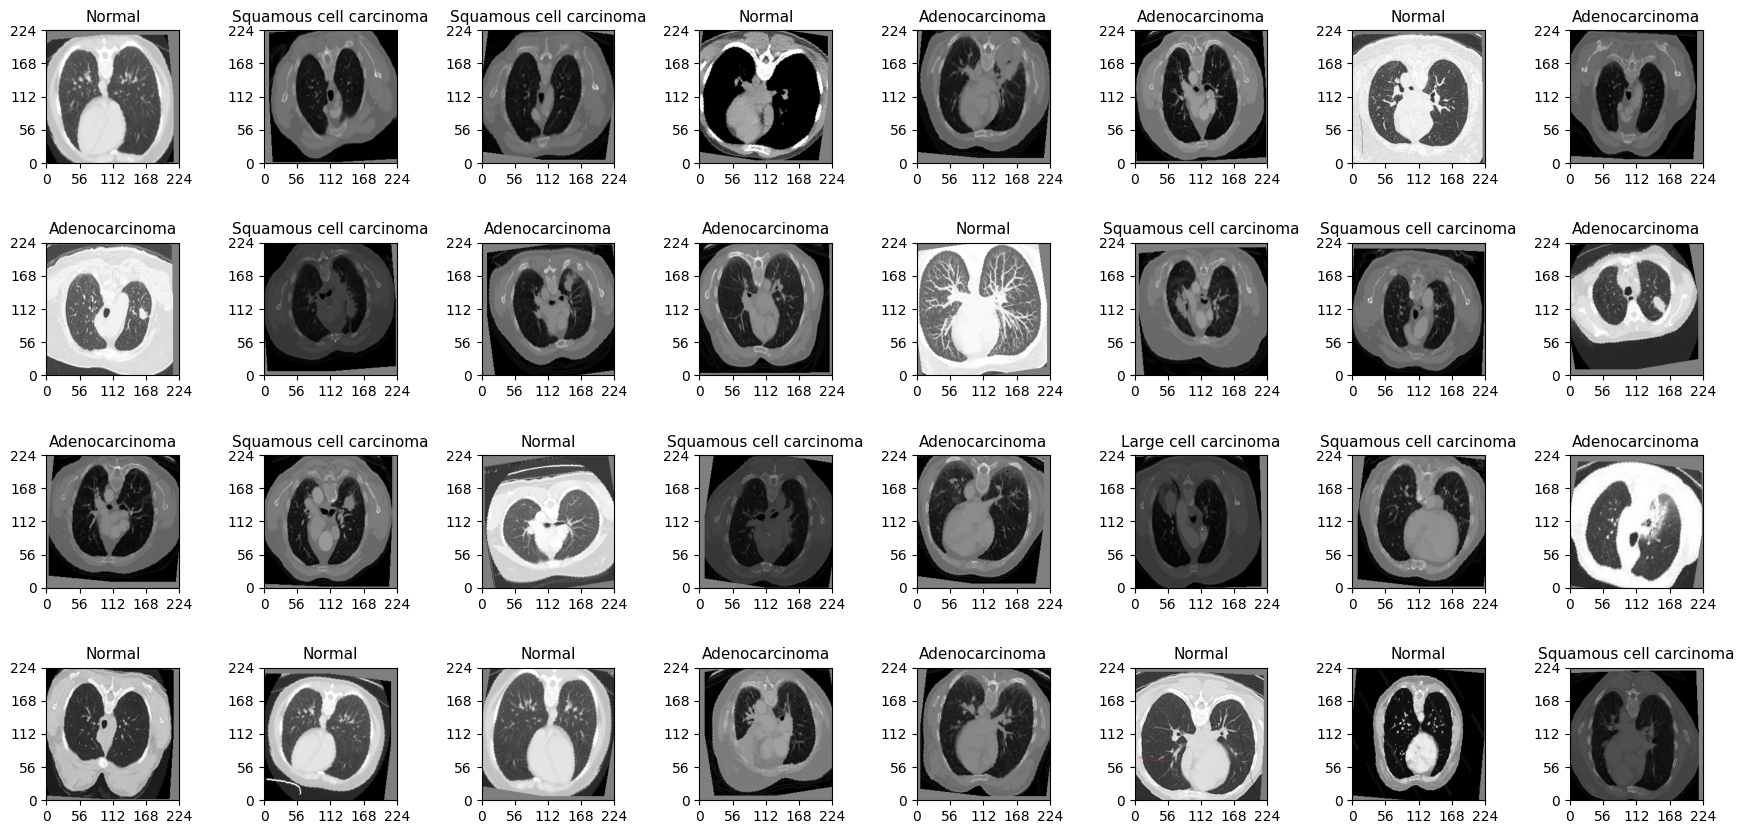

In [3]:
#print(train_dataset.classes)
#print(train_dataset.class_to_idx)
# 4 Classes -> Adenocarcinoma, Large cell carcinoma, Normal, Squamous cell carcinoma
num_classes = len(train_dataset.classes)
labelclass = {0:"Adenocarcinoma", 1:"Large cell carcinoma", 2:"Normal", 3:"Squamous cell carcinoma"}
imgs, label_idxs = next(iter(train_loader))

# denormalize images. 
imgs = imgs * 0.5 + 0.5
imgs = imgs.clamp(0,1)

fig, ax = plt.subplots(4,8, figsize=(22,10))
    
for row in range(4):
    for col in range(8):
        index = col+row*8
        title = labelclass[label_idxs[index].item()]
        ax[row][col].imshow(imgs[index].permute(1,2,0))
        ax[row][col].set_title(title, fontsize=11)
        ax[row][col].set_xlim(0,img_size)
        ax[row][col].set_ylim(0,img_size)
        ax[row][col].set_xticks([0, 56, 112, 168, 224])
        ax[row][col].set_yticks([0, 56, 112, 168, 224])
        
        
plt.subplots_adjust(hspace=0.6) 

My CNN model from scratch.

In [4]:
class CNN_Net(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        #block1
        self.block1= nn.Sequential(
            nn.Conv2d(3,32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        #block2
        self.block2 = nn.Sequential(
            nn.Conv2d(32,64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(), 
            nn.MaxPool2d(2)
        )

        #block3 
        self.block3 = nn.Sequential(
            nn.Conv2d(64,128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        #block4
        self.block4 = nn.Sequential(
            nn.Conv2d(128,256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )
        
        #block5
        self.block5 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        
        #classifier.
        self.classifier = nn.Sequential(
            nn.Linear(512*7*7, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(128, num_classes),
        )
        
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = torch.flatten(x,1)
        x = self.classifier(x)
        return x

summary of my CNN model.

In [5]:
model = CNN_Net(num_classes)
summary(model, input_size=(32, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
CNN_Net                                  [32, 4]                   --
├─Sequential: 1-1                        [32, 32, 112, 112]        --
│    └─Conv2d: 2-1                       [32, 32, 224, 224]        896
│    └─BatchNorm2d: 2-2                  [32, 32, 224, 224]        64
│    └─ReLU: 2-3                         [32, 32, 224, 224]        --
│    └─MaxPool2d: 2-4                    [32, 32, 112, 112]        --
├─Sequential: 1-2                        [32, 64, 56, 56]          --
│    └─Conv2d: 2-5                       [32, 64, 112, 112]        18,496
│    └─BatchNorm2d: 2-6                  [32, 64, 112, 112]        128
│    └─ReLU: 2-7                         [32, 64, 112, 112]        --
│    └─MaxPool2d: 2-8                    [32, 64, 56, 56]          --
├─Sequential: 1-3                        [32, 128, 28, 28]         --
│    └─Conv2d: 2-9                       [32, 128, 56, 56]         73,856
│    

resnet model - pre-trained model.

In [6]:
model_resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

model_resnet18.fc = nn.Sequential (
    nn.Linear(512,512),
    nn.Dropout(0.2),
    nn.Linear(512,256),
    nn.Linear(256, num_classes)
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 145MB/s] 


In [7]:
summary(model_resnet18, input_size=(32, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [32, 4]                   --
├─Conv2d: 1-1                            [32, 64, 112, 112]        9,408
├─BatchNorm2d: 1-2                       [32, 64, 112, 112]        128
├─ReLU: 1-3                              [32, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [32, 64, 56, 56]          --
├─Sequential: 1-5                        [32, 64, 56, 56]          --
│    └─BasicBlock: 2-1                   [32, 64, 56, 56]          --
│    │    └─Conv2d: 3-1                  [32, 64, 56, 56]          36,864
│    │    └─BatchNorm2d: 3-2             [32, 64, 56, 56]          128
│    │    └─ReLU: 3-3                    [32, 64, 56, 56]          --
│    │    └─Conv2d: 3-4                  [32, 64, 56, 56]          36,864
│    │    └─BatchNorm2d: 3-5             [32, 64, 56, 56]          128
│    │    └─ReLU: 3-6                    [32, 64, 56, 56]          --
│

In [8]:
def epoch_runner(model, X_loader, criterion, optimizer, device, task='train'):
    if task == 'train':
        model.train()
        grad_state = torch.enable_grad()
    elif task in ['test','valid']:
        model.eval()
        grad_state = torch.no_grad()
    else:
        # throw exception.
        raise ValueError("task argument must be train, valid, or test")
        
    
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with grad_state:
        for images, labels in X_loader:
            images = images.to(device)
            labels = labels.to(device)

            #forward.
            outputs = model(images)
            loss = criterion(outputs, labels)

            #backpropogation for only training task.
            if task == 'train':
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            running_loss += loss.item()
        
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

    # metrics.
    epoch_loss = running_loss / len(X_loader)
    epoch_acc = accuracy_score(all_labels,all_preds)
    precision = precision_score(all_labels, all_preds, average="macro", zero_division=0)
    recall = recall_score(all_labels, all_preds, average="macro", zero_division=0)
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    #cm = confusion_matrix(all_labels, all_preds)
    #report = classification_report(all_labels, all_preds)
    
    return epoch_loss, epoch_acc, precision, recall, f1#, cm

In [9]:
def fit(model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        epochs,
        device):

    best_valid_f1 = 0.0
    history = {
        "train_loss": [],
        "train_acc": [],
        "valid_loss": [],
        "valid_acc": [],
        "valid_precision":[],
        "valid_recall":[],
        "valid_f1":[]
    }

    for epoch in range(epochs):

        train_loss, train_acc, train_p, train_r, train_f1 = epoch_runner(
            model, train_loader, criterion, optimizer, device, task = 'train'
        )

        valid_loss, valid_acc, valid_p, valid_r, valid_f1 = epoch_runner(
            model, val_loader, criterion, None, device, task='valid'
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        
        history["valid_loss"].append(valid_loss)
        history["valid_acc"].append(valid_acc)
        history["valid_precision"].append(valid_p)
        history["valid_recall"].append(valid_r)
        history["valid_f1"].append(valid_f1)

        # save best model based on highest f1-score.
        if valid_f1 > best_valid_f1:
            best_valid_f1 = valid_f1
            torch.save(model.state_dict(), "best_model.pth")
            
        print(f""" Epoch {epoch+1}/{epochs}
        Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}
        Valid Loss: {valid_loss:.4f} | Valid Acc: {valid_acc:.4f} | Valid Precision: {valid_p:.4f} | Valid Recall: {valid_r:.4f} | Valid F1: {valid_f1:.4f}
        """)

    return history

criterion and hyper parameters.

In [10]:
# loss function and optimizer.
lr = 0.0001
criterion = nn.CrossEntropyLoss()
optimizer_model = torch.optim.Adam(model.parameters(), lr=lr)
optimizer_model_resnet18 = torch.optim.Adam(model_resnet18.parameters(), lr=lr)

result of my CNN model.

In [11]:
print("device : ", device)
print("Results of my CNN model with 5 epochs")
print("_____________________________________")

history_mycnn = fit(
    model=model,
    train_loader=train_loader,
    val_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer_model,
    epochs=5,
    device=device)

device :  cpu
Results of my CNN model with 5 epochs
_____________________________________
 Epoch 1/5
        Train Loss: 1.1166 | Train Acc: 0.4796
        Valid Loss: 1.4844 | Valid Acc: 0.2917 | Valid Precision: 0.1417 | Valid Recall: 0.2688 | Valid F1: 0.1856
        
 Epoch 2/5
        Train Loss: 0.9892 | Train Acc: 0.5220
        Valid Loss: 1.1381 | Valid Acc: 0.4444 | Valid Precision: 0.4442 | Valid Recall: 0.4727 | Valid F1: 0.4271
        
 Epoch 3/5
        Train Loss: 0.9349 | Train Acc: 0.5563
        Valid Loss: 1.0167 | Valid Acc: 0.4861 | Valid Precision: 0.5450 | Valid Recall: 0.4944 | Valid F1: 0.4586
        
 Epoch 4/5
        Train Loss: 0.9192 | Train Acc: 0.5742
        Valid Loss: 0.9968 | Valid Acc: 0.4861 | Valid Precision: 0.6378 | Valid Recall: 0.4960 | Valid F1: 0.4299
        
 Epoch 5/5
        Train Loss: 0.8600 | Train Acc: 0.5922
        Valid Loss: 1.0343 | Valid Acc: 0.5694 | Valid Precision: 0.4861 | Valid Recall: 0.5668 | Valid F1: 0.5205
        


result of resnet18 model.

In [12]:
print("device : ", device)
print("Results of resnet 18 model with 5 epochs")
print("_____________________________________")

history_resnet18 = fit(
    model=model_resnet18,
    train_loader=train_loader,
    val_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer_model_resnet18,
    epochs=5,
    device=device)

device :  cpu
Results of resnet 18 model with 5 epochs
_____________________________________
 Epoch 1/5
        Train Loss: 0.9697 | Train Acc: 0.5856
        Valid Loss: 0.8435 | Valid Acc: 0.5278 | Valid Precision: 0.7252 | Valid Recall: 0.5731 | Valid F1: 0.5128
        
 Epoch 2/5
        Train Loss: 0.5207 | Train Acc: 0.8091
        Valid Loss: 0.6448 | Valid Acc: 0.6806 | Valid Precision: 0.7212 | Valid Recall: 0.7039 | Valid F1: 0.7040
        
 Epoch 3/5
        Train Loss: 0.2502 | Train Acc: 0.9250
        Valid Loss: 0.9069 | Valid Acc: 0.6111 | Valid Precision: 0.7721 | Valid Recall: 0.6646 | Valid F1: 0.6045
        
 Epoch 4/5
        Train Loss: 0.1596 | Train Acc: 0.9527
        Valid Loss: 0.4057 | Valid Acc: 0.8750 | Valid Precision: 0.8884 | Valid Recall: 0.8933 | Valid F1: 0.8876
        
 Epoch 5/5
        Train Loss: 0.1319 | Train Acc: 0.9576
        Valid Loss: 0.3988 | Valid Acc: 0.8611 | Valid Precision: 0.9118 | Valid Recall: 0.8677 | Valid F1: 0.8786
      

Comparison between mycnn model adn resnet18, with respect to loss, and accuracy indicators for the validation dataset.

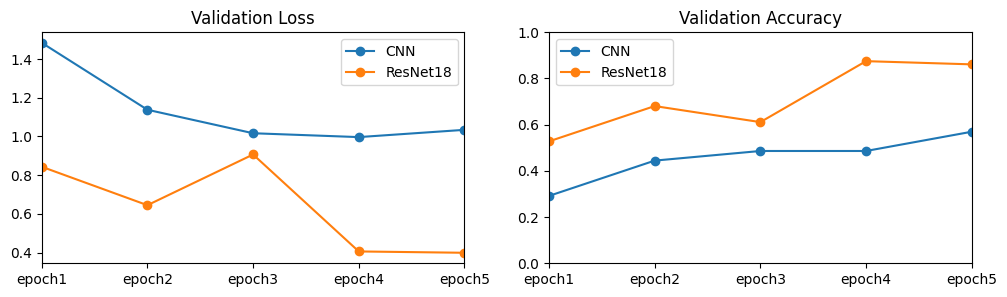

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
# Loss
ax[0].plot(history_mycnn["valid_loss"], label="CNN", marker='o')
ax[0].plot(history_resnet18["valid_loss"], label="ResNet18", marker='o')
ax[0].set_title("Validation Loss")
ax[0].set_xticks([0,1,2,3,4])
ax[0].set_xticklabels(['epoch1', 'epoch2', 'epoch3', 'epoch4', 'epoch5'])
ax[0].set_xlim(0,4)
ax[0].legend()

# Accuracy
ax[1].plot(history_mycnn["valid_acc"], label="CNN", marker='o')
ax[1].plot(history_resnet18["valid_acc"], label="ResNet18", marker='o')
ax[1].set_title("Validation Accuracy")
ax[1].set_xticks([0,1,2,3,4])
ax[1].set_xticklabels(['epoch1', 'epoch2', 'epoch3', 'epoch4', 'epoch5'])
ax[1].set_xlim(0,4)
ax[1].set_ylim(0,1)
ax[1].legend()

plt.show()

Testing both models.

In [14]:
test_loss_mycnn, test_acc_mycnn, test_p_mycnn, test_r_mycnn, test_f1_mycnn = epoch_runner(
    model,
    test_loader,
    criterion,
    optimizer=None,
    device=device,
    task="test"
)


test_loss_resnet18, test_acc_resnet18, test_p_resnet18, test_r_resnet18, test_f1_resnet18 = epoch_runner(
    model_resnet18,
    test_loader,
    criterion,
    optimizer=None,
    device=device,
    task="test"
)

Comparison of both models with test datasets.

In [15]:
comparison_results = pd.DataFrame({
    "Model": ["MyCNN", "ResNet18"],
    "Test Accuracy": [test_acc_mycnn, test_acc_resnet18],
    "Test Precision": [test_p_mycnn, test_p_resnet18],
    "Test Recall": [test_r_mycnn, test_r_resnet18],
    "Test F1": [test_f1_mycnn, test_f1_resnet18],
})
print(comparison_results)

      Model  Test Accuracy  Test Precision  Test Recall   Test F1
0     MyCNN       0.368254        0.474602     0.512296  0.399099
1  ResNet18       0.844444        0.890936     0.855542  0.864473


prediction vs true labels for one batch.

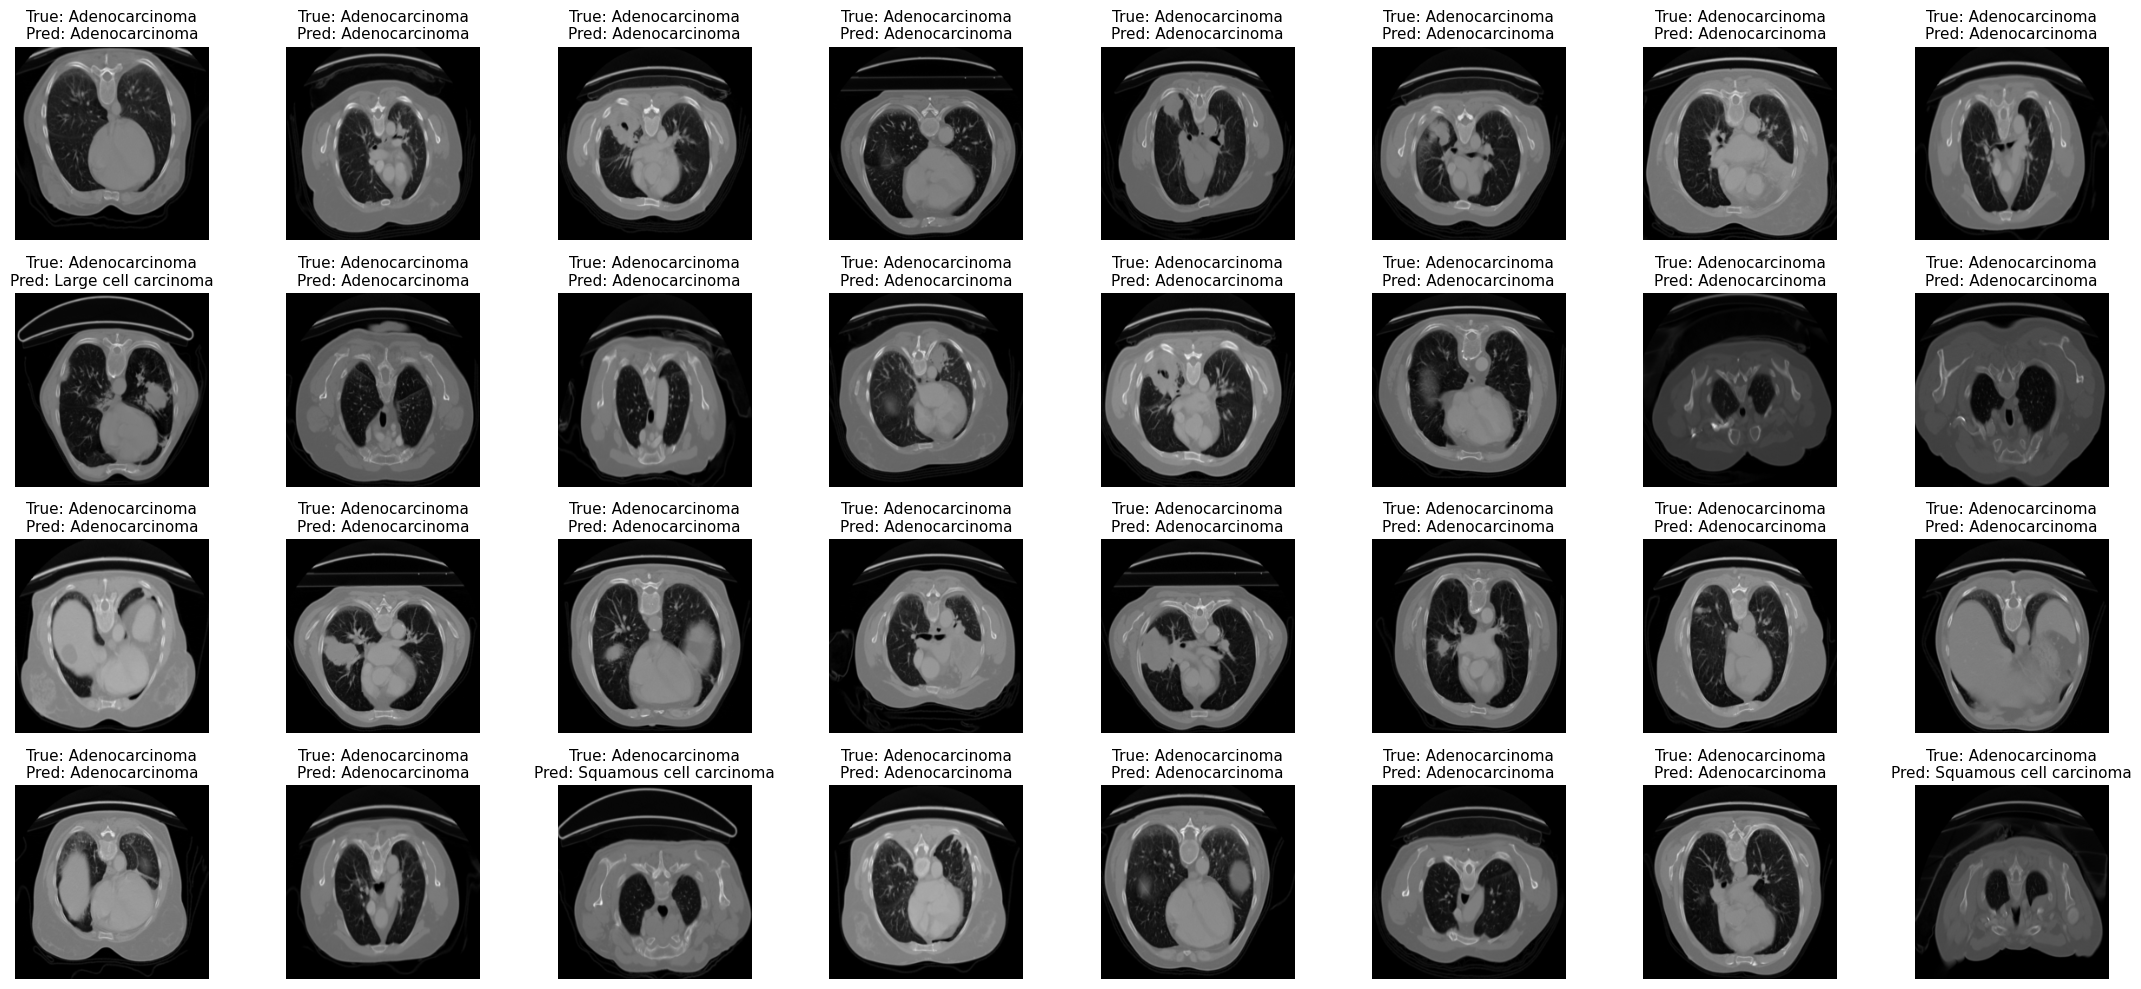

In [16]:
model_resnet18.eval()
imgs, label_idxs = next(iter(test_loader))
imgs = imgs.to(device)

with torch.no_grad():
    outputs = model_resnet18(imgs)
    preds = outputs.argmax(dim=1).cpu()

# denormalize for visualization
imgs = imgs.cpu() * 0.5 + 0.5
imgs = imgs.clamp(0, 1)

fig, ax = plt.subplots(4, 8, figsize=(22, 10))

for row in range(4):
    for col in range(8):
        index = col + row * 8
        
        true_label = labelclass[label_idxs[index].item()]
        pred_label = labelclass[preds[index].item()]

        ax[row][col].imshow(imgs[index].permute(1, 2, 0))
        ax[row][col].set_title(f"True: {true_label}\nPred: {pred_label}", fontsize=11)
        ax[row][col].set_xlim(0, img_size)
        ax[row][col].set_ylim(0, img_size)
        ax[row][col].set_xticks([0, 56, 112, 168, 224])
        ax[row][col].set_yticks([0, 56, 112, 168, 224])
        ax[row][col].axis("off")

plt.tight_layout()
plt.show()